In [ ]:
!pip install -q timm transformers accelerate sentencepiece chromadb sentence-transformers

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.3/23.3 MB 74.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 278.2/278.2 kB 21.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 119.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.2/19.2 MB 94.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.2/137.2 kB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.6/204.6 kB 18.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 94.7/94.7 kB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.6/60.6 kB 3.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currentl

In [1]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

import timm

from transformers import AutoProcessor, AutoModel

In [2]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cpu


## Dataset

In [ ]:
# # from google.colab import drive

# # drive.mount('/content/drive')



# !unzip -q "Skin v2.zip" -d "/content/Skin v2"

[Skin v2.zip]
  End-of-central-directory signature not found.  Either this file is not
  a zipfile, or it constitutes one disk of a multi-part archive.  In the
  latter case the central directory and zipfile comment will be found on
  the last disk(s) of this archive.
unzip:  cannot find zipfile directory in one of Skin v2.zip or
        Skin v2.zip.zip, and cannot find Skin v2.zip.ZIP, period.


In [ ]:
# !rm -rf "/content/Skin v2/__MACOSX"

In [5]:
DATASET_DIR = "/Users/vaishaligarg/Desktop/medical_rag/dataset/Skin v2"

print("Dataset path:")
print(DATASET_DIR)

print("\nPath exists:", os.path.exists(DATASET_DIR))

Dataset path:
/Users/vaishaligarg/Desktop/medical_rag/dataset/Skin v2

Path exists: True


## checking five classes

In [6]:
print("Classes found in dataset:\n")

for folder in sorted(os.listdir(DATASET_DIR)):
    folder_path = os.path.join(DATASET_DIR, folder)

    if os.path.isdir(folder_path):
        print(folder)

Classes found in dataset:

acne
blackheads
dark_spots
pores
wrinkles


## Efficientnet-b2 preprocessing

In [7]:
efficientnet_transform = transforms.Compose([

    transforms.Resize((256, 256)),

    transforms.CenterCrop((224, 224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

## load dataset

In [8]:
dataset = datasets.ImageFolder(
    root=DATASET_DIR,
    transform=efficientnet_transform
)

print("Total images:", len(dataset))

print("\nClasses:")
print(dataset.classes)

print("\nClass mapping:")
print(dataset.class_to_idx)

Total images: 9770

Classes:
['acne', 'blackheads', 'dark_spots', 'pores', 'wrinkles']

Class mapping:
{'acne': 0, 'blackheads': 1, 'dark_spots': 2, 'pores': 3, 'wrinkles': 4}


## tarin/valid/test split

In [9]:
total_size = len(dataset)

train_size = int(0.70 * total_size)
val_size = int(0.15 * total_size)
test_size = total_size - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(
    dataset,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))

Training images: 6839
Validation images: 1465
Testing images: 1466


## dataloaders

In [10]:
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("DataLoaders created successfully!")

DataLoaders created successfully!


In [11]:
# check one batch
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels:", labels)

Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])
Labels: tensor([1, 0, 2, 1, 1, 0, 2, 3, 0, 4, 1, 0, 0, 2, 1, 2])


In [12]:
# visualize dataset
def denormalize(image):
    mean = torch.tensor(
        [0.485, 0.456, 0.406]
    ).view(3, 1, 1)

    std = torch.tensor(
        [0.229, 0.224, 0.225]
    ).view(3, 1, 1)


    image = image * std + mean

    return torch.clamp(image, 0, 1)

In [13]:
images, labels = next(iter(train_loader))

plt.figure(figsize=(12, 8))

for i in range(8):

    image = denormalize(images[i])

    image = image.permute(1, 2, 0)

    plt.subplot(2, 4, i + 1)

    plt.imshow(image)

    plt.title(dataset.classes[labels[i].item()])

    plt.axis("off")

plt.tight_layout()
plt.show()

KeyboardInterrupt: 

## EFFICIENTNET-B2


In [14]:
efficientnet = timm.create_model(
    "efficientnet_b2",
    pretrained=True,
    num_classes=5
)

efficientnet = efficientnet.to(device)

print(efficientnet)

EfficientNet(
  (conv_stem): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
  (bn1): BatchNormAct2d(
    32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True
    (drop): Identity()
    (act): SiLU(inplace=True)
  )
  (blocks): Sequential(
    (0): Sequential(
      (0): DepthwiseSeparableConv(
        (conv_dw): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
        (bn1): BatchNormAct2d(
          32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True
          (drop): Identity()
          (act): SiLU(inplace=True)
        )
        (aa): Identity()
        (se): SqueezeExcite(
          (conv_reduce): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
          (act1): SiLU(inplace=True)
          (conv_expand): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
          (gate): Sigmoid()
        )
        (conv_pw): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bi

In [15]:
# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.AdamW(
    efficientnet.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

# Learning-rate scheduler
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=1
)

print("Optimizer and scheduler ready!")

Optimizer and scheduler ready!


In [16]:
# training function
def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)

        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(loader)

    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [17]:
# validation function
def validate(model, loader, criterion):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)

            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(loader)

    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [19]:
# TRAIN EFFICIENTNET-B2
# WITH BEST MODEL CHECKPOINT

EPOCHS = 5

MODEL_PATH = "/Users/vaishaligarg/Desktop/medical_rag/test_images/efficientnet_b2_skin_issues.pth"

best_val_acc = 0.0

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        efficientnet,
        train_loader,
        criterion,
        optimizer
    )

    val_loss, val_acc = validate(
        efficientnet,
        val_loader,
        criterion
    )
    scheduler.step(val_loss)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_acc:.2f}% "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_acc:.2f}%"
    )

    # Save only the best validation model
    if val_acc > best_val_acc:

        best_val_acc = val_acc

        torch.save(
            efficientnet.state_dict(),
            MODEL_PATH
        )

        print(
            f"Best model saved! "
            f"Validation Accuracy: {val_acc:.2f}%"
        )

print("\nBest Validation Accuracy:", best_val_acc)
print("Best model saved at:", MODEL_PATH)

TimeoutError: Caught TimeoutError in DataLoader worker process 0.
Original Traceback (most recent call last):
  File "/Users/vaishaligarg/miniforge3/envs/mac_gpu/lib/python3.10/site-packages/torch/utils/data/_utils/worker.py", line 374, in _worker_loop
    data = fetcher.fetch(index)  # type: ignore[possibly-undefined]
  File "/Users/vaishaligarg/miniforge3/envs/mac_gpu/lib/python3.10/site-packages/torch/utils/data/_utils/fetch.py", line 52, in fetch
    data = self.dataset.__getitems__(possibly_batched_index)
  File "/Users/vaishaligarg/miniforge3/envs/mac_gpu/lib/python3.10/site-packages/torch/utils/data/dataset.py", line 443, in __getitems__
    return [self.dataset[self.indices[idx]] for idx in indices]
  File "/Users/vaishaligarg/miniforge3/envs/mac_gpu/lib/python3.10/site-packages/torch/utils/data/dataset.py", line 443, in <listcomp>
    return [self.dataset[self.indices[idx]] for idx in indices]
  File "/Users/vaishaligarg/miniforge3/envs/mac_gpu/lib/python3.10/site-packages/tor

In [ ]:
# import hashlib

# MODEL_PATH = "/content/efficientnet_b2_skin_issues.pth"

# with open(MODEL_PATH, "rb") as f:
#     file_hash = hashlib.sha256(f.read()).hexdigest()

# print("Colab SHA256:")
# print(file_hash)

In [ ]:
# import hashlib

# IMAGE_PATH = "/content/testgirl.jpeg"

# with open(IMAGE_PATH, "rb") as f:
#     image_hash = hashlib.sha256(f.read()).hexdigest()

# print("Colab image SHA256:")
# print(image_hash)

In [ ]:
# ============================================
# LOAD BEST EFFICIENTNET MODEL
# ============================================

efficientnet.load_state_dict(
    torch.load(
        MODEL_PATH,
        map_location=device
    )
)

efficientnet = efficientnet.to(device)
efficientnet.eval()

print("Best EfficientNet-B2 model loaded successfully!")

Best EfficientNet-B2 model loaded successfully!


In [ ]:
# test efficientnet
test_loss, test_accuracy = validate(
    efficientnet,
    test_loader,
    criterion
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Test Loss: 0.1872548375170521
Test Accuracy: 95.83901773533424


In [ ]:
# skin condition prediction
class_names = dataset.classes

def predict_skin_condition(model, image_tensor):

    model.eval()

    image_tensor = image_tensor.unsqueeze(0).to(device)

    with torch.no_grad():

        outputs = model(image_tensor)

        probabilities = torch.softmax(outputs, dim=1)

        predicted_class = torch.argmax(
            probabilities,
            dim=1
        ).item()

    return (
        class_names[predicted_class],
        probabilities[0].cpu().numpy()
    )

In [ ]:
# test prediction
image, label = test_dataset[0]

predicted_class, probabilities = predict_skin_condition(
    efficientnet,
    image
)

print("Actual class:", class_names[label])
print("Predicted class:", predicted_class)

print("\nProbabilities:")

for class_name, probability in zip(
    class_names,
    probabilities
):
    print(
        f"{class_name}: {probability:.4f}"
    )

Actual class: dark spots
Predicted class: dark spots

Probabilities:
acne: 0.0000
blackheades: 0.0000
dark spots: 1.0000
pores: 0.0000
wrinkles: 0.0000


# **Siglip**

In [ ]:
# SIGLIP_MODEL = "google/siglip-base-patch16-224"

# siglip_processor = AutoProcessor.from_pretrained(
#     SIGLIP_MODEL
# )

# siglip_model = AutoModel.from_pretrained(
#     SIGLIP_MODEL
# )

# siglip_model = siglip_model.to(device)

# siglip_model.eval()

# print("SigLIP loaded successfully.")

preprocessor_config.json:   0%|          | 0.00/368 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/432 [00:00<?, ?B/s]

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.


tokenizer_config.json:   0%|          | 0.00/711 [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  798kB            

spiece.model: downloading bytes:           |  0.00B            

... (2 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  813MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/408 [00:00<?, ?it/s]

SigLIP loaded successfully.


Image size: (1179, 968)
Image mode: RGB


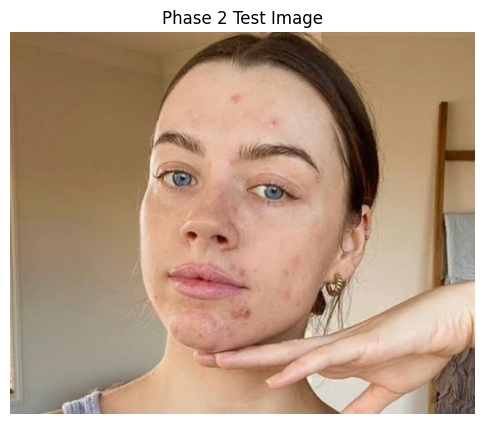

EfficientNet tensor shape: torch.Size([3, 224, 224])

Skin-condition predictions:
acne           : 0.0001
blackheades    : 0.0000
dark spots     : 0.9999
pores          : 0.0000
wrinkles       : 0.0000

Predicted class: dark spots
Confidence: 0.9999


In [ ]:
# # ============================================
# # REAL-TIME PHASE 2 TEST IMAGE
# # ============================================

# from PIL import Image
# import matplotlib.pyplot as plt

# TEST_IMAGE_PATH = "/content/testgirl.jpeg"

# test_image = Image.open(
#     TEST_IMAGE_PATH
# ).convert("RGB")

# print("Image size:", test_image.size)
# print("Image mode:", test_image.mode)

# plt.figure(figsize=(6, 6))
# plt.imshow(test_image)
# plt.axis("off")
# plt.title("Phase 2 Test Image")
# plt.show()

# # ============================================
# # EFFICIENTNET-B2 BRANCH
# # ============================================

# efficientnet_image = efficientnet_transform(
#     test_image
# )

# print(
#     "EfficientNet tensor shape:",
#     efficientnet_image.shape
# )

# predicted_class, probabilities = predict_skin_condition(
#     efficientnet,
#     efficientnet_image
# )

# print("\nSkin-condition predictions:")

# for class_name, probability in zip(
#     class_names,
#     probabilities
# ):
#     print(
#         f"{class_name:15s}: {probability:.4f}"
#     )

# print("\nPredicted class:", predicted_class)

# predicted_confidence = probabilities[
#     class_names.index(predicted_class)
# ]

# print(
#     "Confidence:",
#     f"{predicted_confidence:.4f}"
# )

In [ ]:
# # ============================================
# # SIGLIP BRANCH
# # ============================================

# siglip_inputs = siglip_processor(
#     images=test_image,
#     return_tensors="pt"
# )

# siglip_inputs = {
#     key: value.to(device)
#     for key, value in siglip_inputs.items()
# }

# print("SigLIP input prepared successfully.")

SigLIP input prepared successfully.


In [ ]:
# with torch.no_grad():

#     siglip_outputs = siglip_model.get_image_features(
#         **siglip_inputs
#     )

# print("SigLIP image embedding shape:")
# print(siglip_outputs.pooler_output.shape)

SigLIP image embedding shape:
torch.Size([1, 768])


In [ ]:
# # normalize image embedding
# embeddings = siglip_outputs.pooler_output

# image_embedding = embeddings / embeddings.norm(
#     dim=-1,
#     keepdim=True
# )

# print("Normalized embedding shape:")
# print(image_embedding.shape)

# print("Embedding norm:")
# print(image_embedding.norm(dim=-1))

Normalized embedding shape:
torch.Size([1, 768])
Embedding norm:
tensor([1.], device='cuda:0')


In [ ]:
# # ============================================
# # STEP 7 — VISION PROJECTION
# # ============================================

# import torch
# import torch.nn as nn

# # SigLIP embedding dimension
# SIGLIP_DIM = image_embedding.shape[-1]

# # Gemma 3 text hidden dimension
# GEMMA_HIDDEN_DIM = 2560

# print("SigLIP embedding dimension:", SIGLIP_DIM)
# print("Gemma hidden dimension:", GaEMMA_HIDDEN_DIM)


# class VisionProjection(nn.Module):

#     def __init__(
#         self,
#         input_dim,
#         output_dim
#     ):
#         super().__init__()

#         self.projection = nn.Linear(
#             input_dim,
#             output_dim
#         )

#     def forward(self, x):

#         return self.projection(x)


# vision_projection = VisionProjection(
#     input_dim=SIGLIP_DIM,
#     output_dim=GEMMA_HIDDEN_DIM
# ).to(device)

# print("Vision Projection created successfully!")

SigLIP embedding dimension: 768
Gemma hidden dimension: 2560
Vision Projection created successfully!


In [ ]:
# # ============================================
# # STEP 8 — PROJECT SIGLIP EMBEDDING
# # ============================================

# vision_projection.eval()

# with torch.no_grad():

#     projected_image_features = vision_projection(
#         image_embedding
#     )

# print(
#     "Projected image feature shape:",
#     projected_image_features.shape
# )

# # ============================================
# # STEP 9 — CREATE IMAGE TOKENS
# # ============================================

# image_tokens = projected_image_features.unsqueeze(1)

# print(
#     "Image tokens shape:",
#     image_tokens.shape
# )

Projected image feature shape: torch.Size([1, 2560])
Image tokens shape: torch.Size([1, 1, 2560])


In [ ]:
# # ============================================
# # STEP 10 — VERIFY IMAGE BRANCH
# # ============================================

# print("=" * 50)
# print("IMAGE BRANCH VERIFICATION")
# print("=" * 50)

# print("Input image:")
# print("  ", test_image.size)

# print("\nEfficientNet:")
# print("  Predicted class:", predicted_class)
# print("  Confidence:", f"{predicted_confidence:.4f}")

# print("\nSigLIP:")
# print("  Embedding:", image_embedding.shape)

# print("\nVision Projection:")
# print("  Projected:", projected_image_features.shape)

# print("\nImage Tokens:")
# print("  Tokens:", image_tokens.shape)

# print("=" * 50)

IMAGE BRANCH VERIFICATION
Input image:
   (1179, 968)

EfficientNet:
  Predicted class: dark spots
  Confidence: 0.9999

SigLIP:
  Embedding: torch.Size([1, 768])

Vision Projection:
  Projected: torch.Size([1, 2560])

Image Tokens:
  Tokens: torch.Size([1, 1, 2560])
